# 01 · Data inventory and integrity

What data is on disk, whether the tract lists agree across sources, what the submission looks like and where the regions are. First step of the EDA; nothing is modelled here.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pathlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "data").exists())
DATA, OUT, ANALYSIS = ROOT / "data", ROOT / "eda_outputs", ROOT / "analysis_outputs"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25, "axes.titlesize": 11, "axes.labelsize": 9})
REG = ["maricopa-az", "northern-ca", "eastern-ok", "south-central-tx", "eastern-wa"]
NAME = {"maricopa-az": "Maricopa AZ", "northern-ca": "Northern CA", "eastern-ok": "Eastern OK", "south-central-tx": "S-C Texas", "eastern-wa": "Eastern WA"}
COL = dict(zip(REG, ["#e07b39", "#c0504d", "#6a9e4f", "#3b6fb6", "#8e6bbf"]))

## 1. What files do we have?

In [2]:
rows = []
for p in sorted(list(DATA.rglob("*")) + list(ANALYSIS.glob("*"))):
    if p.is_file(): rows.append((str(p.relative_to(ROOT)).replace("\\", "/"), p.suffix, round(p.stat().st_size / 1e6, 2)))
inv = pd.DataFrame(rows, columns=["file", "type", "MB"])
print(inv.groupby("type").agg(files=("file", "size"), MB=("MB", "sum")).round(1).to_string())
print(); print(inv[inv.type.isin([".parquet", ".csv"])].to_string(index=False))

          files    MB
type                 
.csv         16   0.8
.geojson      7  10.2
.json         1   0.4
.md           1   0.0
.parquet      5  19.1

                                                                   file     type   MB
                       analysis_outputs/building_update_monthly.parquet .parquet 0.01
                         analysis_outputs/inventory_parquet_footers.csv     .csv 0.02
                                   analysis_outputs/model_frame.parquet .parquet 1.57
                          analysis_outputs/scored_tracts_strata.parquet .parquet 6.38
                          analysis_outputs/tract_analysis_table.parquet .parquet 9.64
                     analysis_outputs/tract_overture_aggregates.parquet .parquet 1.51
                            data/boundaries/eastern-ok-tract-geoids.csv     .csv 0.02
                            data/boundaries/eastern-wa-tract-geoids.csv     .csv 0.01
                           data/boundaries/maricopa-az-tract-geoids.csv

**Takeaway:** the local package has no raw Overture layers: only tract lists, ACS housing, sample submissions and boundaries under `data/`, plus two committed tract-level tables in `analysis_outputs/` (Overture aggregates and strata). This EDA is therefore at tract level. `analysis_outputs/` also holds derived tables (`model_frame`, `tract_analysis_table`); they are not used here, the base table is rebuilt from the primary sources in notebook 02.

## 2. Is the scored tract list consistent across sources?
Sample submission is the authoritative list of scored tracts. Compare it with the frozen geoid lists, the ACS table and the two tract-level tables.

                  submission  geoid list   ACS  Overture aggregates  strata
maricopa-az             1593        1593  1593                 1593    1593
northern-ca              591         591   591                  591     591
eastern-ok              1192        1192  1192                 1192    1192
south-central-tx        6003        6010  6010                 6003    6003
eastern-wa               415         415   415                  415     415

in geoid list but not scored: {'south-central-tx': ['48007990000', '48061990000', '48261990000', '48273990000', '48321990000', '48355990000', '48489990000']}
duplicate GEOIDs: submission 0 | aggregates 0 | strata 0
same tract in two regions: 0 | aggregates match submission: True | strata match: True
GEOID lengths: {11: 9794}


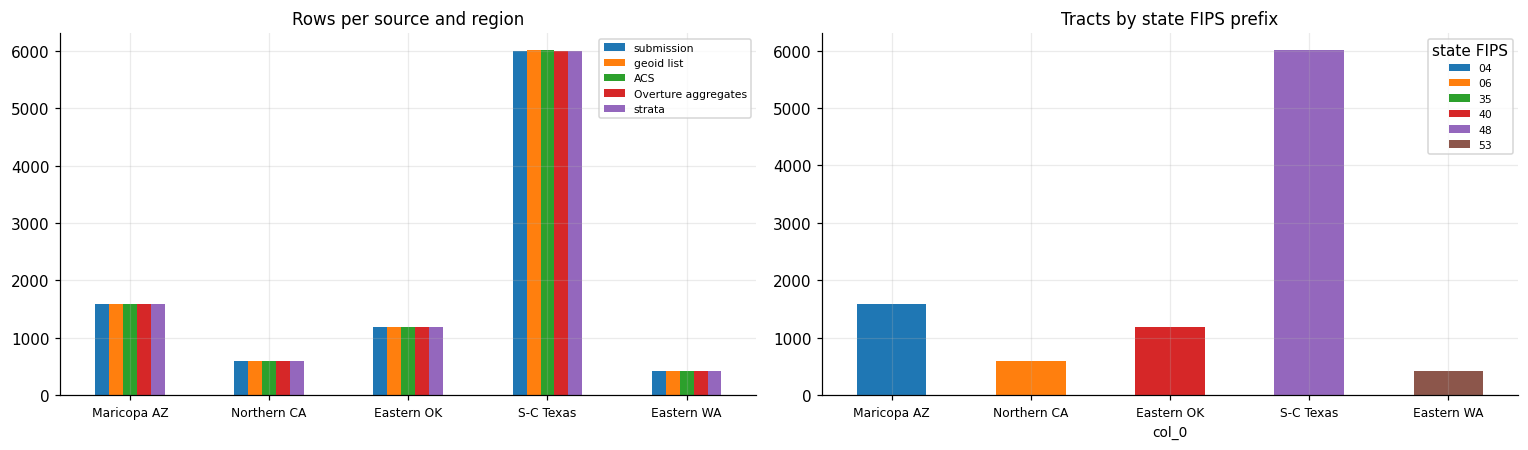

In [3]:
def keys(p): return pd.read_csv(p, dtype={"GEOID": str}).GEOID
sub = {r: pd.read_csv(DATA / "reference" / r / f"{r}-sample-submission.csv", dtype={"GEOID": str}) for r in REG}
geo = {r: keys(DATA / "boundaries" / f"{r}-tract-geoids.csv") for r in REG}
acs = {r: pd.read_csv(DATA / "reference" / r / f"{r}-census-acs-housing.csv", dtype=str) for r in REG}
agg = pd.read_parquet(ANALYSIS / "tract_overture_aggregates.parquet"); stp = pd.read_parquet(ANALYSIS / "scored_tracts_strata.parquet")
T = pd.DataFrame({"submission": {r: len(sub[r]) for r in REG}, "geoid list": {r: len(geo[r]) for r in REG}, "ACS": {r: len(acs[r]) for r in REG},
                  "Overture aggregates": agg.groupby("region").size(), "strata": stp.groupby("region").size()}).reindex(REG)
only_geo = {r: sorted(set(geo[r]) - set(sub[r].GEOID)) for r in REG}
print(T.to_string()); print("\nin geoid list but not scored:", {r: v for r, v in only_geo.items() if v})
print("duplicate GEOIDs: submission", sum(s.GEOID.duplicated().sum() for s in sub.values()), "| aggregates", agg.GEOID.duplicated().sum(), "| strata", stp.GEOID.duplicated().sum())
allsub = pd.concat(sub.values()).GEOID; print("same tract in two regions:", allsub.duplicated().sum(), "| aggregates match submission:", set(agg.GEOID) == set(allsub), "| strata match:", set(stp.GEOID) == set(allsub))
print("GEOID lengths:", allsub.str.len().value_counts().to_dict())
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2)); T.plot.bar(ax=ax[0], rot=0); ax[0].set_xticklabels([NAME[r] for r in REG], fontsize=8); ax[0].set_title("Rows per source and region"); ax[0].legend(fontsize=7)
st = pd.crosstab(pd.concat(sub.values()).GEOID.str[:2], pd.concat([pd.Series(r, index=sub[r].index) for r in REG]).values).reindex(columns=REG); st.T.plot.bar(stacked=True, ax=ax[1], rot=0); ax[1].set_xticklabels([NAME[r] for r in REG], fontsize=8); ax[1].set_title("Tracts by state FIPS prefix"); ax[1].legend(title="state FIPS", fontsize=7)
plt.tight_layout(); plt.show()

**Takeaway:** the tract lists agree exactly: 9,794 scored tracts, no duplicates, no tract in two regions, and the Overture and strata tables cover precisely those tracts. The geoid list and ACS file for Texas have 6,010 rows against 6,003 scored: the 7 extra are water-only tracts dropped from scoring. Texas is 6,003 of 9,794 tracts (61%).

## 3. What does the sample submission look like?

In [4]:
S = pd.concat([s.assign(region=r) for r, s in sub.items()], ignore_index=True)
print(S.dtypes.to_string()); print("\nvalues per column:", {c: S[c].nunique() for c in S.columns if c not in ("GEOID", "region")}, "| all zero:", bool((S[["transport_gap", "building_gap", "poi_gap", "coverage_gap_score"]] == 0).all().all()))
print("\nscored rows per region:", S.region.value_counts().reindex(REG).to_dict())

GEOID                  object
transport_gap         float64
building_gap          float64
poi_gap               float64
coverage_gap_score    float64
region                 object

values per column: {'transport_gap': 1, 'building_gap': 1, 'poi_gap': 1, 'coverage_gap_score': 1} | all zero: True

scored rows per region: {'maricopa-az': 1593, 'northern-ca': 591, 'eastern-ok': 1192, 'south-central-tx': 6003, 'eastern-wa': 415}


**Takeaway:** the submission has one row per tract with four numeric columns (`transport_gap`, `building_gap`, `poi_gap`, `coverage_gap_score`), all zeros as a template. The score is the mean of the components that are defined for each tract, so it is the final column we must predict.

## 4. Where are the regions?

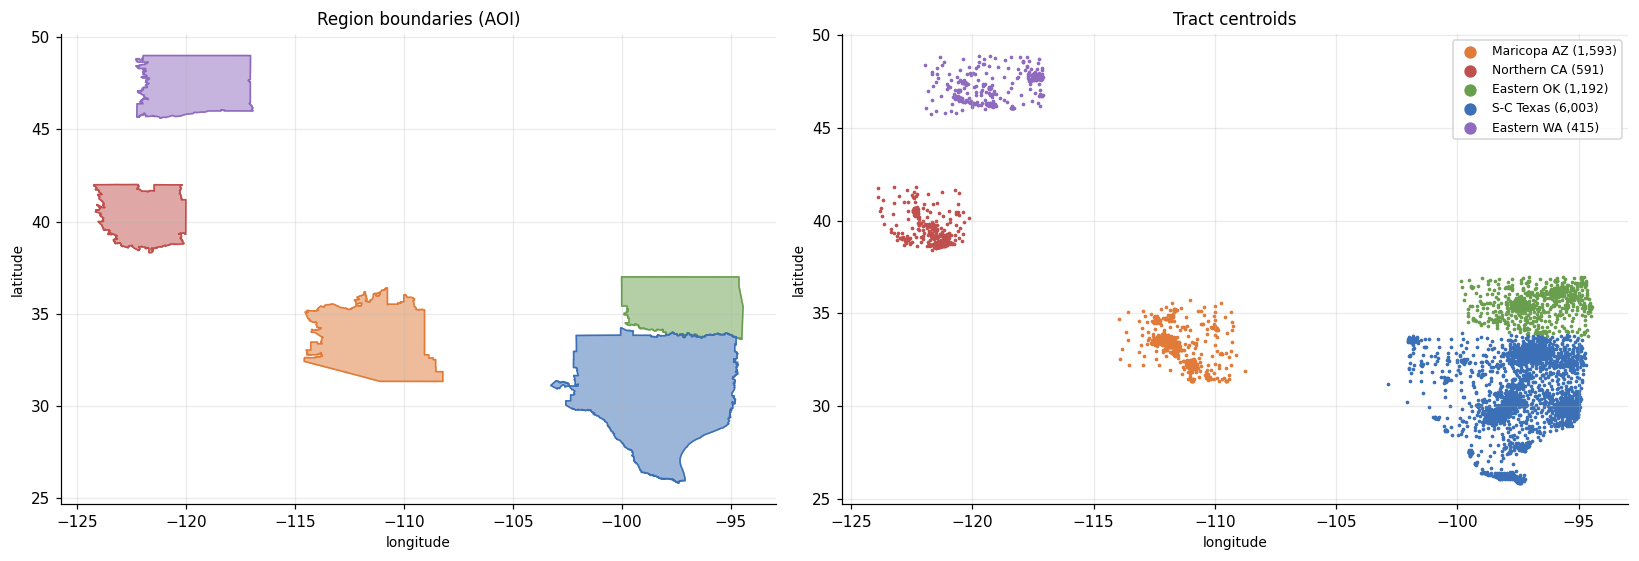

                     lon    lat  tracts
region                                 
maricopa-az      -111.71  33.28    1593
northern-ca      -121.62  39.21     591
eastern-ok        -96.82  35.60    1192
south-central-tx  -97.05  30.75    6003
eastern-wa       -118.90  47.17     415


In [5]:
import json
stp[["INTPTLON", "INTPTLAT"]] = stp[["INTPTLON", "INTPTLAT"]].astype(float)      # stored as text in the table
fig, ax = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1, 1.1]})
for r in REG:
    gj = json.load(open(DATA / "boundaries" / f"{r}-aoi.geojson")); feats = gj["features"] if "features" in gj else [gj]
    for ft in feats:
        g = ft["geometry"]; polys = g["coordinates"] if g["type"] == "MultiPolygon" else [g["coordinates"]]
        for poly in polys: xy = np.array(poly[0]); ax[0].fill(xy[:, 0], xy[:, 1], color=COL[r], alpha=.5); ax[0].plot(xy[:, 0], xy[:, 1], color=COL[r], lw=1)
    c = stp[stp.region == r]; ax[1].scatter(c.INTPTLON, c.INTPTLAT, s=2, color=COL[r], label=f"{NAME[r]} ({len(c):,})")
ax[0].set_title("Region boundaries (AOI)"); ax[1].set_title("Tract centroids"); ax[1].legend(markerscale=5, fontsize=8)
for a in ax: a.set(xlabel="longitude", ylabel="latitude")
plt.tight_layout(); plt.show()
print(stp.groupby("region").agg(lon=("INTPTLON", "mean"), lat=("INTPTLAT", "mean"), tracts=("GEOID", "size")).reindex(REG).round(2).to_string())

**Takeaway:** the regions are far apart except Eastern Oklahoma and S-C Texas, which meet at the Red River. The 'south-central' Texas region is in fact most of eastern Texas, from the Rio Grande to the Oklahoma border, and its tract centroids cluster densely around a few metro areas. The other regions have one or two dense clusters each.

## 5. Column inventory of the two tract tables

Overture aggregates: (9794, 43) {'numeric': 41, 'bool': 0, 'text': 2}
Strata: (9794, 233) {'numeric': 176, 'bool': 31, 'text': 26}
{'buildings': 10, 'roads': 16, 'POIs': 11, 'transit/infra': 3}


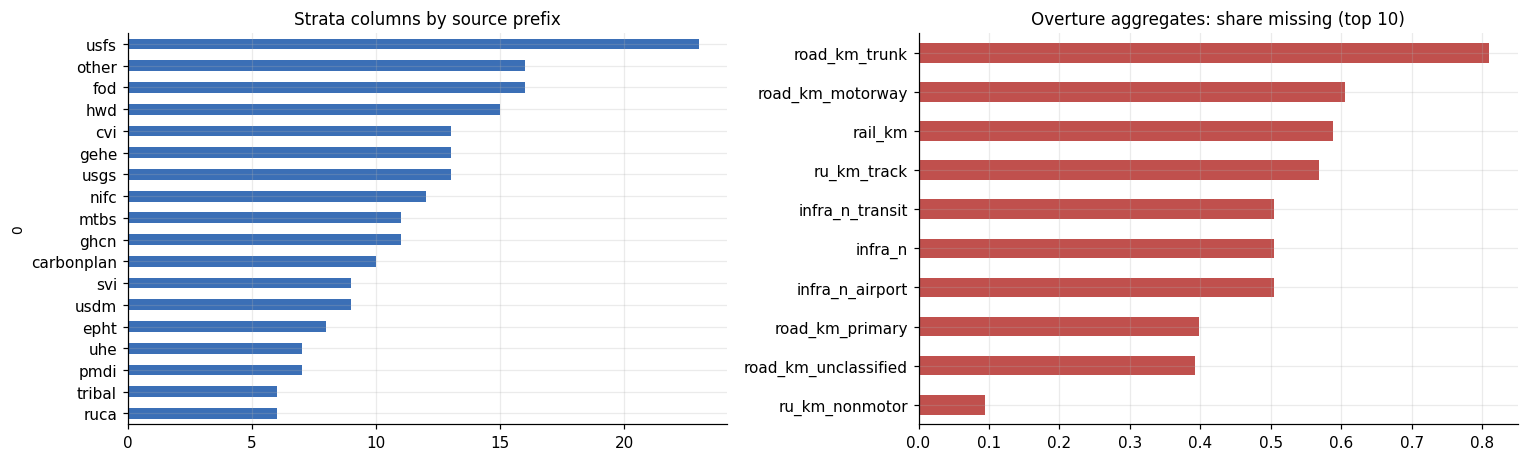

In [6]:
def kinds(d):
    return pd.Series({"numeric": d.select_dtypes("number").shape[1], "bool": d.select_dtypes("bool").shape[1], "text": d.select_dtypes(["object", "string"]).shape[1]})
pref = stp.columns.str.extract(r"^([a-z]+)_")[0].fillna("other").value_counts()
print("Overture aggregates:", agg.shape, kinds(agg).to_dict()); print("Strata:", stp.shape, kinds(stp).to_dict())
grp = {"buildings": "bldg_", "roads": "road_|ru_|rail", "POIs": "poi_", "transit/infra": "infra_"}
print({k: int(agg.columns.str.contains(v).sum()) for k, v in grp.items()})
fig, ax = plt.subplots(1, 2, figsize=(14, 4.3)); pref.head(18).sort_values().plot.barh(ax=ax[0], color="#3b6fb6"); ax[0].set_title("Strata columns by source prefix")
agg.isna().mean().sort_values(ascending=False).head(10).sort_values().plot.barh(ax=ax[1], color="#c0504d"); ax[1].set_title("Overture aggregates: share missing (top 10)")
plt.tight_layout(); plt.show()

**Takeaway:** strata is the wide table (233 columns: demographics, vulnerability indices and many hazard layers); Overture aggregates is narrow (43 columns: buildings, roads, POIs, rail, transit). Neither has a target column, so the next notebook joins them with ACS housing units into one base table.